# Signal analysis

### Goals of the notebook
- Analyse the correlation betweern each information on the input vector (meta data, demographic data, radiomics ) with the correctness label


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os


In [4]:
c2_data_effusion = pd.read_csv("/zhome/d0/a/221493/thesis/results/C2_custom/effusion/c2_data.csv")
c2_data_effusion_extended = pd.read_csv("/zhome/d0/a/221493/thesis/results/C2_custom/effusion/c2_data_extended.csv")

In [5]:
c2_data_effusion

,path,prob,true,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,...,Aorta_original_firstorder_Mean,Aorta_original_firstorder_Median,Aorta_original_firstorder_Minimum,Aorta_original_firstorder_Range,Aorta_original_firstorder_RobustMeanAbsoluteDeviation,Aorta_original_firstorder_RootMeanSquared,Aorta_original_firstorder_Skewness,Aorta_original_firstorder_TotalEnergy,Aorta_original_firstorder_Uniformity,Aorta_original_firstorder_Variance
0,CheXpert-v1.0-small/train/patient00005/study1/...,0.041813,0.0,-0.001189,-0.001188,0.002148,0.004988,-0.102837,0.176574,-0.001303,...,567.888093,646.393494,-65.630211,979.157249,150.293437,617.916926,-0.809970,1.172191e+08,0.039672,59324.441149
1,CheXpert-v1.0-small/train/patient00006/study1/...,0.215630,0.0,-0.001187,-0.003957,0.007097,0.003399,-0.039104,0.381481,-0.001332,...,34.056039,48.996605,-689.254150,1126.734589,96.362326,185.642746,-0.652183,3.511803e+07,0.041965,33303.415247
2,CheXpert-v1.0-small/train/patient00008/study1/...,0.989880,1.0,-0.001258,-0.002985,0.004605,0.001783,0.038349,0.398952,-0.001282,...,286.560282,357.584167,-409.044739,1017.673828,95.900233,347.399748,-1.382682,1.007733e+08,0.057587,38569.789807
3,CheXpert-v1.0-small/train/patient00008/study2/...,0.803541,1.0,-0.001191,-0.002817,0.002820,0.001346,0.057698,0.703989,-0.001344,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,CheXpert-v1.0-small/train/patient00010/study1/...,0.022438,0.0,-0.001185,-0.000546,0.002303,0.005171,-0.117948,-0.032563,-0.001290,...,213.656361,221.533264,-713.253662,1709.125610,216.630374,441.249354,-0.057772,1.177941e+08,0.020209,149051.951785
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45150,CheXpert-v1.0-small/train/patient47343/study4/...,0.254230,0.0,-0.001193,-0.000748,0.004452,0.002485,0.093880,0.295449,-0.001299,...,-78.911822,7.484866,-748.935486,996.037933,140.442993,239.189061,-0.828364,3.015041e+07,0.041562,50984.331080
45151,CheXpert-v1.0-small/train/patient47343/study5/...,0.190490,0.0,-0.001195,-0.000950,0.003514,0.003379,0.001992,0.100993,-0.001304,...,166.455575,249.356003,-590.689453,1055.035339,102.029540,280.504147,-1.452701,4.004943e+07,0.056241,50975.118192
45152,CheXpert-v1.0-small/train/patient47344/study4/...,0.999278,1.0,-0.001212,-0.003044,0.003746,-0.000369,0.070971,0.830508,-0.001302,...,437.703904,506.113647,-268.893646,969.057587,82.569345,474.512460,-1.599859,1.508586e+08,0.076489,33577.367070
45153,CheXpert-v1.0-small/train/patient47344/study3/...,0.997425,1.0,-0.001218,-0.002594,0.004547,0.002813,-0.001783,0.486586,-0.001291,...,369.637714,417.336212,-455.067108,1149.506439,98.581153,413.320162,-1.236381,1.482835e+08,0.050213,34201.516570


In [6]:
c2_data_effusion_extended

,path,prob,true,emb_0,emb_1,emb_2,emb_3,emb_4,emb_5,emb_6,...,Weasand_original_shape2D_PixelSurface,Weasand_original_shape2D_Sphericity,Weasand_perimeter,age_pred,patient_id,race_asian,race_black,race_white,sex_female,sex_male
0,CheXpert-v1.0-small/train/patient00005/study1/...,0.041813,0.0,-0.001189,-0.001186,0.002146,0.004988,-0.102878,0.176344,-0.001303,...,1232.0,0.441704,151.539104,41.602314,patient00005,0.002152,2.898194e-02,0.968866,0.000007,9.999933e-01
1,CheXpert-v1.0-small/train/patient00006/study1/...,0.215646,0.0,-0.001187,-0.003954,0.007097,0.003398,-0.039020,0.381182,-0.001332,...,2313.0,0.458716,848.256921,51.069099,patient00006,0.000082,9.728379e-01,0.027080,0.629882,3.701182e-01
2,CheXpert-v1.0-small/train/patient00008/study1/...,0.989891,1.0,-0.001258,-0.002981,0.004603,0.001782,0.038358,0.399419,-0.001282,...,1704.0,0.457761,726.014279,73.590202,patient00008,0.000032,1.025554e-07,0.999968,0.010737,9.892625e-01
3,CheXpert-v1.0-small/train/patient00008/study2/...,0.803473,1.0,-0.001191,-0.002815,0.002819,0.001348,0.057667,0.703849,-0.001344,...,494.0,0.625289,285.539104,71.747986,patient00008,0.000003,9.215846e-07,0.999996,0.015747,9.842526e-01
4,CheXpert-v1.0-small/train/patient00010/study1/...,0.022443,0.0,-0.001185,-0.000544,0.002301,0.005169,-0.117937,-0.033050,-0.001290,...,1508.0,0.508993,615.931020,56.875008,patient00010,0.000454,2.969435e-04,0.999249,0.999999,1.270073e-06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45150,CheXpert-v1.0-small/train/patient47343/study4/...,0.254282,0.0,-0.001193,-0.000746,0.004451,0.002484,0.093905,0.294997,-0.001299,...,1219.0,0.500583,562.433546,54.558731,patient47343,0.001062,5.852066e-03,0.993085,1.000000,2.231963e-07
45151,CheXpert-v1.0-small/train/patient47343/study5/...,0.190549,0.0,-0.001195,-0.000948,0.003515,0.003376,0.002050,0.100450,-0.001304,...,1177.0,0.493049,558.090401,45.389763,patient47343,0.000389,3.357243e-04,0.999276,1.000000,7.858079e-08
45152,CheXpert-v1.0-small/train/patient47344/study4/...,0.999278,1.0,-0.001212,-0.003042,0.003746,-0.000372,0.070899,0.830360,-0.001302,...,1113.0,0.571880,467.546244,80.073486,patient47344,0.000312,2.706236e-04,0.999417,0.999963,3.720483e-05
45153,CheXpert-v1.0-small/train/patient47344/study3/...,0.997430,1.0,-0.001218,-0.002592,0.004545,0.002813,-0.001787,0.486378,-0.001291,...,1329.0,0.515983,569.688379,70.140518,patient47344,0.000306,1.673754e-04,0.999527,0.999999,7.611677e-07


## Derive correctness label and feature groups

In [7]:
df = c2_data_effusion_extended.copy()

# Binary correctness label: 1 if prediction matches ground truth
df['correct'] = ((df['prob'] > 0.5634).astype(int) == df['true'].astype(int)).astype(int)
print(f"Accuracy: {df['correct'].mean():.3f}  |  N={len(df)}")

# Feature group masks
emb_cols       = [c for c in df.columns if c.startswith('emb_')]
demo_cols      = ['age_pred', 'race_asian', 'race_black', 'race_white', 'sex_female', 'sex_male']
radiomics_cols = [c for c in df.columns if c not in emb_cols + demo_cols + ['path', 'prob', 'true', 'correct', 'patient_id']]

print(f"Embeddings: {len(emb_cols)}  |  Demographics: {len(demo_cols)}  |  Radiomics: {len(radiomics_cols)}")

Accuracy: 0.917  |  N=45155
Embeddings: 1024  |  Demographics: 6  |  Radiomics: 786


## Point-biserial correlations with correctness

Pearson correlation between each numeric feature and the binary `correct` label is equivalent to the point-biserial correlation.

In [8]:
def top_correlations(df, feature_cols, target='correct', n=20):
    """Return absolute Pearson correlations between feature_cols and target, sorted descending."""
    corr = (
        df[feature_cols + [target]]
        .corr()[target]
        .drop(target)
        .dropna()
    )
    return corr.reindex(corr.abs().sort_values(ascending=False).index)

corr_demo      = top_correlations(df, demo_cols)
corr_emb       = top_correlations(df, emb_cols)
corr_radiomics = top_correlations(df, radiomics_cols, n=20)

print("=== Demographics ===")
print(corr_demo.to_string())
print("\n=== Top-20 Embeddings ===")
print(corr_emb.head(20).to_string())
print("\n=== Top-20 Radiomics ===")
print(corr_radiomics.head(20).to_string())

=== Demographics ===
sex_male     -0.008916
sex_female    0.008916
race_asian    0.007822
age_pred      0.006804
race_white   -0.003573
race_black   -0.002525

=== Top-20 Embeddings ===
emb_905    0.285330
emb_801    0.271362
emb_765    0.268221
emb_900    0.262833
emb_754    0.261400
emb_892    0.261271
emb_745   -0.257032
emb_639    0.255091
emb_828    0.249616
emb_757    0.249093
emb_914    0.248803
emb_702    0.248348
emb_759    0.248252
emb_924    0.247017
emb_951    0.244694
emb_918    0.244509
emb_896    0.243698
emb_636    0.239940
emb_931    0.239171
emb_713    0.238490

=== Top-20 Radiomics ===
margin                                             0.307019
pred                                               0.272271
Heart_original_firstorder_Minimum                  0.119329
Heart_original_firstorder_Range                   -0.112970
Right Lung_original_firstorder_Skewness           -0.109283
Heart_original_glcm_SumAverage                    -0.104881
Heart_original_glcm_JointAve

## Visualise top correlations per group

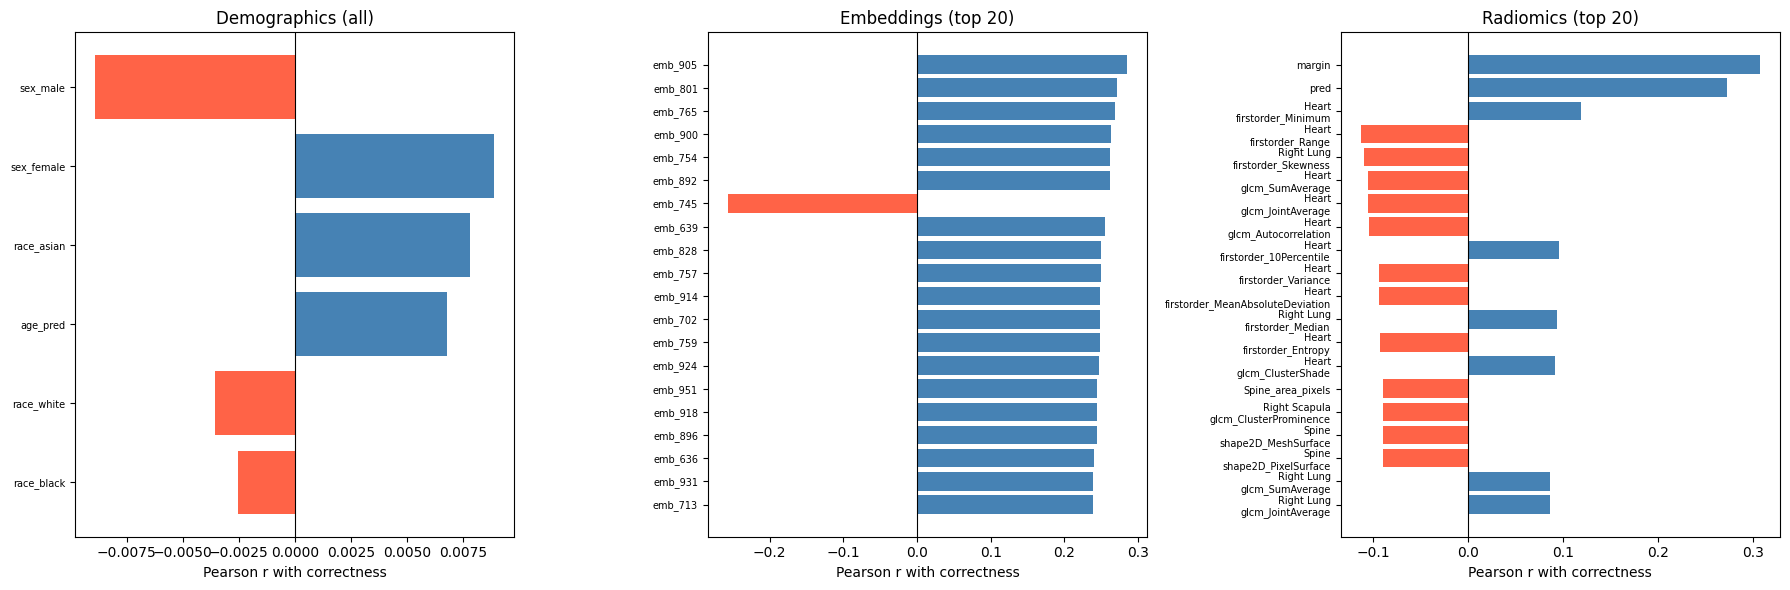

In [9]:
TOP_N = 20

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

def plot_corr(ax, corr_series, title, top_n=TOP_N):
    top = corr_series.head(top_n)
    colors = ['steelblue' if v > 0 else 'tomato' for v in top.values]
    ax.barh(range(len(top)), top.values, color=colors)
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels([c.replace('_original_', '\n') for c in top.index], fontsize=7)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel('Pearson r with correctness')
    ax.set_title(title)
    ax.invert_yaxis()

plot_corr(axes[0], corr_demo,      'Demographics (all)')
plot_corr(axes[1], corr_emb,       f'Embeddings (top {TOP_N})')
plot_corr(axes[2], corr_radiomics, f'Radiomics (top {TOP_N})')

plt.tight_layout()
plt.savefig('/zhome/d0/a/221493/thesis/results/signal_correlations.png', dpi=150, bbox_inches='tight')
plt.show()

## Overall strongest signals across all groups

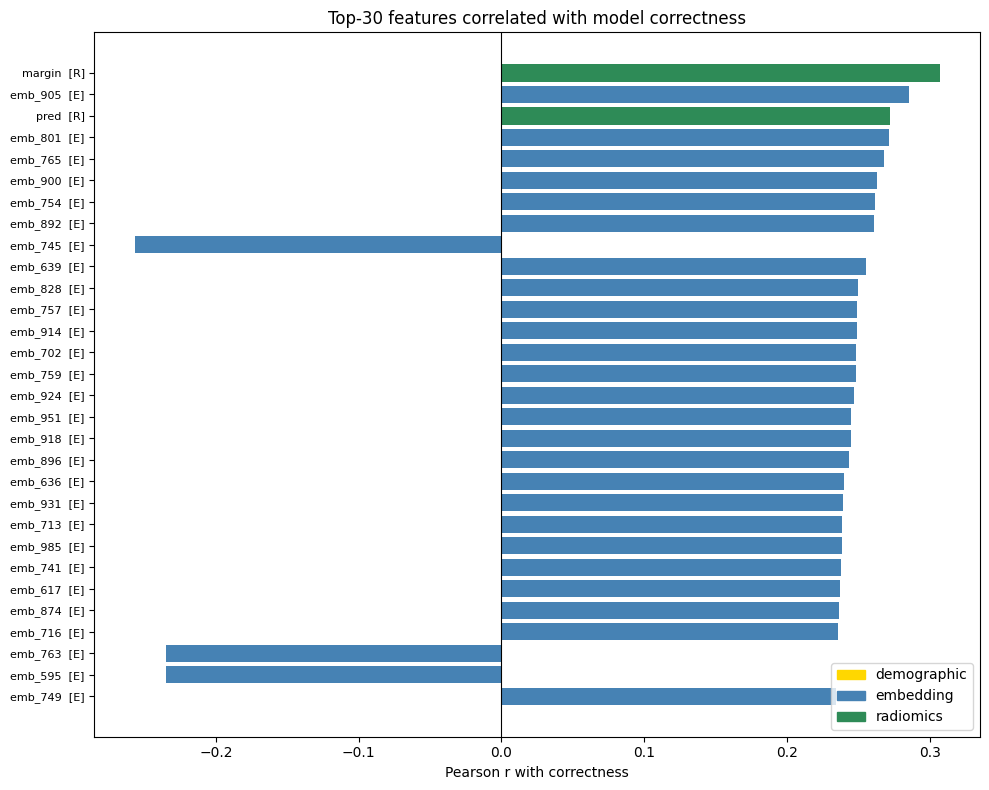

,r,group,abs_r
margin,0.307019,radiomics,0.307019
emb_905,0.285330,embedding,0.285330
pred,0.272271,radiomics,0.272271
emb_801,0.271362,embedding,0.271362
emb_765,0.268221,embedding,0.268221
emb_900,0.262833,embedding,0.262833
emb_754,0.261400,embedding,0.261400
emb_892,0.261271,embedding,0.261271
emb_745,-0.257032,embedding,0.257032
emb_639,0.255091,embedding,0.255091


In [10]:
all_corr = pd.concat([
    corr_demo.rename('r').to_frame().assign(group='demographic'),
    corr_emb.rename('r').to_frame().assign(group='embedding'),
    corr_radiomics.rename('r').to_frame().assign(group='radiomics'),
])

all_corr['abs_r'] = all_corr['r'].abs()
top_overall = all_corr.nlargest(30, 'abs_r')

fig, ax = plt.subplots(figsize=(10, 8))
group_colors = {'demographic': 'gold', 'embedding': 'steelblue', 'radiomics': 'seagreen'}
colors = [group_colors[g] for g in top_overall['group']]
ax.barh(range(len(top_overall)), top_overall['r'].values, color=colors)
ax.set_yticks(range(len(top_overall)))
ax.set_yticklabels([f"{row.Index.replace('_original_', '·')}  [{row.group[0].upper()}]"
                    for row in top_overall.itertuples()], fontsize=8)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Pearson r with correctness')
ax.set_title('Top-30 features correlated with model correctness')
ax.invert_yaxis()

from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=v, label=k) for k, v in group_colors.items()], loc='lower right')
plt.tight_layout()
plt.savefig('/zhome/d0/a/221493/thesis/results/signal_correlations_top30.png', dpi=150, bbox_inches='tight')
plt.show()

top_overall

## AUROC comparison by feature group

In [11]:
from sklearn.metrics import roc_auc_score

correct = df['correct']
prob    = df['prob']
margin  = (df['prob'] - 0.5).abs()  # distance from decision boundary

# Best single embedding dimension (already computed, no model needed)
best_emb = corr_emb.abs().idxmax()

auroc_prob      = roc_auc_score(correct, prob)
auroc_margin    = roc_auc_score(correct, margin)
auroc_best_emb  = roc_auc_score(correct, df[best_emb])

print(f"AUROC — prob:          {auroc_prob:.4f}")
print(f"AUROC — margin |p-0.5|:{auroc_margin:.4f}")
print(f"AUROC — best emb ({best_emb}): {auroc_best_emb:.4f}")

AUROC — prob:          0.7363
AUROC — margin |p-0.5|:0.8362
AUROC — best emb (emb_905): 0.8046


## Radiomics signal by anatomical region

                       mean_abs_r  max_abs_r  n_features
region                                                  
margin                   0.307019   0.307019           1
pred                     0.272271   0.272271           1
Heart                    0.051010   0.119329          56
Right Scapula            0.046897   0.089541          56
Right Hilus Pulmonis     0.043719   0.073515          56
Aorta                    0.040362   0.065253          56
Left Lung                0.040029   0.079861          56
Right Lung               0.038828   0.109283          56
Left Scapula             0.037775   0.068310          56
Left Hilus Pulmonis      0.035468   0.072642          56
Weasand                  0.035138   0.071096          56
Mediastinum              0.031774   0.058189          56
Spine                    0.031766   0.089737          56
Right Clavicle           0.027514   0.053990          56
Facies Diaphragmatica    0.025452   0.066670          56
Left Clavicle            0.0251

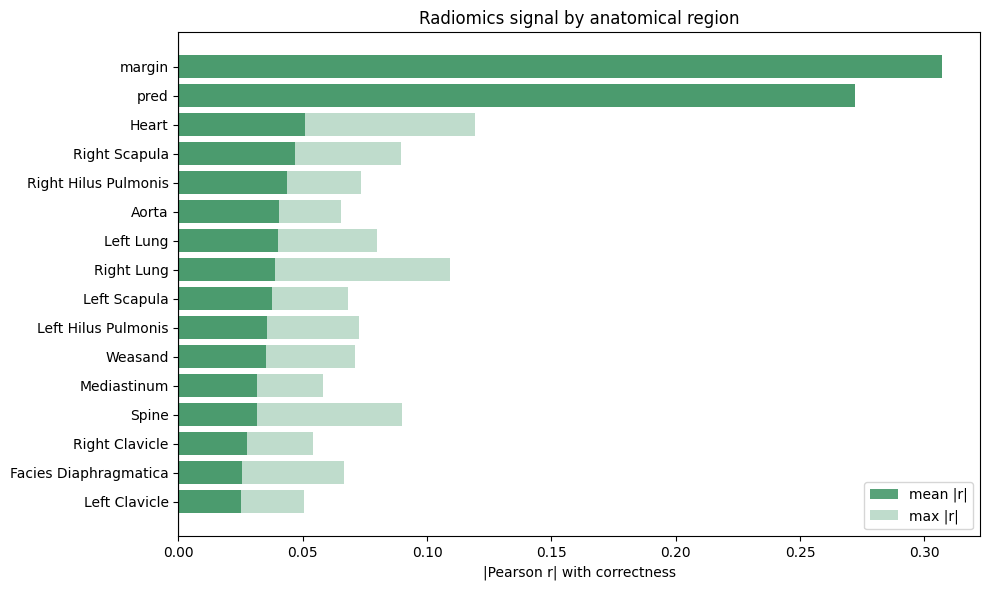

In [12]:
rad_df = corr_radiomics.reset_index()
rad_df.columns = ['feature', 'r']
rad_df['region'] = rad_df['feature'].str.split('_').str[0]

region_signal = (
    rad_df.groupby('region')['r']
    .agg(mean_abs_r=lambda x: x.abs().mean(),
         max_abs_r=lambda x: x.abs().max(),
         n_features='count')
    .sort_values('mean_abs_r', ascending=False)
)

print(region_signal.to_string())

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(region_signal.index, region_signal['mean_abs_r'], color='seagreen', alpha=0.8, label='mean |r|')
ax.barh(region_signal.index, region_signal['max_abs_r'],  color='seagreen', alpha=0.3, label='max |r|')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('|Pearson r| with correctness')
ax.set_title('Radiomics signal by anatomical region')
ax.invert_yaxis()
ax.legend()
plt.tight_layout()
plt.savefig('/zhome/d0/a/221493/thesis/results/signal_by_region.png', dpi=150, bbox_inches='tight')
plt.show()

## Comparison: base file vs extended file

The extended file adds Weasand-region radiomics + predicted demographic attributes (age, race, sex).  
Here we run the same correlation analysis on the **base** file and compare top signals side-by-side.

In [ ]:
df_base = c2_data_effusion.copy()
df_base['correct'] = ((df_base['prob'] > 0.5634).astype(int) == df_base['true'].astype(int)).astype(int)

emb_cols_base = [c for c in df_base.columns if c.startswith('emb_')]
rad_cols_base  = [c for c in df_base.columns if c not in emb_cols_base + ['path', 'prob', 'true', 'correct']]

corr_emb_base = top_correlations(df_base, emb_cols_base)
corr_rad_base = top_correlations(df_base, rad_cols_base)

print("=== Base — Top-20 Embeddings ===")
print(corr_emb_base.head(20).to_string())
print("\n=== Base — Top-20 Radiomics ===")
print(corr_rad_base.head(20).to_string())

In [ ]:
# Side-by-side: top-20 radiomics from base vs extended
TOP = 20

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=False)

def plot_corr_titled(ax, corr_series, title, top_n=TOP):
    top = corr_series.head(top_n)
    colors = ['steelblue' if v > 0 else 'tomato' for v in top.values]
    ax.barh(range(len(top)), top.values, color=colors)
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels([c.replace('_original_', '\n') for c in top.index], fontsize=7)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_xlabel('Pearson r with correctness')
    ax.set_title(title)
    ax.invert_yaxis()

plot_corr_titled(axes[0], corr_rad_base,      f'Base file — Radiomics (top {TOP})')
plot_corr_titled(axes[1], corr_radiomics,     f'Extended file — Radiomics (top {TOP})')
plt.tight_layout()
plt.savefig('/zhome/d0/a/221493/thesis/results/signal_base_vs_extended.png', dpi=150, bbox_inches='tight')
plt.show()

# Summary: new features exclusive to the extended file and their correlations
ext_only_cols = [c for c in df.columns if c not in df_base.columns and c not in ['correct']]
corr_new = top_correlations(df, ext_only_cols)
print(f"\nNew columns in extended ({len(ext_only_cols)} features):")
print(corr_new.to_string())

print(f"\nBest radiomics r — base:     {corr_rad_base.abs().max():.4f}  ({corr_rad_base.abs().idxmax()})")
print(f"Best radiomics r — extended: {corr_radiomics.abs().max():.4f}  ({corr_radiomics.abs().idxmax()})")